# Entrenamiento de EfficientNetB3 y MobileNetV3Small para enfermedades de plantas

Este cuaderno entrena un clasificador multiclase con **14 clases**: las nueve clases de tomate de PlantVillage y las cinco carpetas de clases ubicadas directamente en `dataset_procesado/extracted`. Cada carpeta es la etiqueta de sus im?genes.

Se aplican aumento de datos, parada temprana, pesos preentrenados en ImageNet y regularizaci?n **L1+L2**. MobileNetV3Small se entrena mediante destilaci?n del modelo profesor EfficientNetB3.

> Ejecuta las celdas en orden. El entrenamiento completo requiere TensorFlow y, para un tiempo razonable, una GPU. Los modelos y reportes se guardan en `modelos_multiclase/`.


## Alcance y defensa t?cnica

- **Etiquetas:** se usan las nueve carpetas `Tomato_*` de PlantVillage y las cinco carpetas de clase directamente dentro de `dataset_procesado/extracted`. El nombre de cada carpeta se usa como etiqueta.
- **Separaci?n:** partici?n por clase 70/15/15 con semilla fija; se eliminan duplicados exactos por SHA-256 antes de dividir.
- **Modelo profesor:** EfficientNetB3 con pesos ImageNet; primero se ajusta la cabeza y despu?s se descongela parcialmente la red.
- **Modelo estudiante:** MobileNetV3Small aprende de las etiquetas de carpeta y de las probabilidades del profesor.
- **Regularizaci?n:** Dropout, aumento de datos, L1 y L2 en las capas densas y EarlyStopping.
- **L?mites:** las carpetas extra?das se tratan como etiquetas proporcionadas por su organizaci?n; conviene revisar que sus im?genes correspondan a la clase antes de interpretar las m?tricas. El conjunto puede tener sesgos de fondo, iluminaci?n y origen.


## 1. Entorno, rutas y reproducibilidad

In [1]:
from pathlib import Path
import os, random, json, hashlib, time
import numpy as np
import pandas as pd
import tensorflow as tf
from PIL import Image, UnidentifiedImageError
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)
tf.keras.utils.set_random_seed(SEMILLA)

# Cambia PROYECTO si ejecutas este cuaderno desde otra ubicación.
PROYECTO = Path.cwd()
if not (PROYECTO / "dataset_procesado" / "extracted").exists():
    candidatos = [p for p in [Path.cwd(), Path.cwd().parent] if (p / "dataset_procesado" / "extracted").exists()]
    if candidatos:
        PROYECTO = candidatos[0]
DATOS_EXTRAIDOS = PROYECTO / "dataset_procesado" / "extracted"
SALIDA = PROYECTO / "modelos_multiclase"
SALIDA.mkdir(parents=True, exist_ok=True)
TAMANO = (224, 224)
LOTE = 32
EPOCAS_CABEZA = 12
EPOCAS_AJUSTE = 12
EPOCAS_ESTUDIANTE = 20

print("TensorFlow:", tf.__version__)
print("Dispositivo(s):", tf.config.list_physical_devices())
print("Proyecto:", PROYECTO)
print("Datos extraídos:", DATOS_EXTRAIDOS)
print("Salida:", SALIDA)
assert DATOS_EXTRAIDOS.exists(), ("No encuentro dataset_procesado/extracted. Ejecuta primero la extracción del dataset o cambia DATOS_EXTRAIDOS.")

TensorFlow: 2.21.0
Dispositivo(s): [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]
Proyecto: D:\UNIVERSIDAD COOPERATIVA\9.NOVENO SEMESTRE UCC\Electiva III
Datos extraídos: D:\UNIVERSIDAD COOPERATIVA\9.NOVENO SEMESTRE UCC\Electiva III\dataset_procesado\extracted
Salida: D:\UNIVERSIDAD COOPERATIVA\9.NOVENO SEMESTRE UCC\Electiva III\modelos_multiclase


## 2. Localizar PlantVillage y revisar las categorías etiquetadas

In [2]:
plantvillage_dirs = list(DATOS_EXTRAIDOS.rglob("PlantVillage"))
if len(plantvillage_dirs) != 1:
    raise RuntimeError(f"Se esperaba una carpeta PlantVillage; encontr? {len(plantvillage_dirs)}: {plantvillage_dirs}")
PLANTVILLAGE = plantvillage_dirs[0]
EXTENSIONES = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# Nueve clases de tomate de PlantVillage.
carpetas_clase = {
    p.name: p for p in PLANTVILLAGE.iterdir()
    if p.is_dir() and p.name.startswith("Tomato_")
}
# Cinco clases adicionales organizadas directamente bajo extracted.
# Se excluye la carpeta contenedora 0c... que alberga PlantVillage.
for carpeta in DATOS_EXTRAIDOS.iterdir():
    if not carpeta.is_dir() or carpeta == PLANTVILLAGE.parent:
        continue
    if any(r.is_file() and r.suffix.lower() in EXTENSIONES for r in carpeta.rglob("*")):
        carpetas_clase[carpeta.name] = carpeta

clases = sorted(carpetas_clase)
print("PlantVillage:", PLANTVILLAGE)
print("Carpetas adicionales:", len(carpetas_clase) - 9)
print("N?mero total de clases:", len(clases))
print("Clases:")
for nombre in clases:
    print(" -", nombre)
if len([c for c in clases if c.startswith("Tomato_")]) != 9:
    raise RuntimeError("Se esperaban las 9 clases Tomato_* de PlantVillage.")
if len(carpetas_clase) - 9 != 5:
    raise RuntimeError(f"Se esperaban 5 carpetas de clase adicionales en extracted; encontr? {len(carpetas_clase) - 9}.")


PlantVillage: D:\UNIVERSIDAD COOPERATIVA\9.NOVENO SEMESTRE UCC\Electiva III\dataset_procesado\extracted\0c533816ffe7d8c9\PlantVillage
Carpetas adicionales: 5
N?mero total de clases: 14
Clases:
 - Algod C3 B3n-Verticillium-dahliae-Los-primeros-s C3 ADntomas-son-retraso-del-crecimiento-y-clorosis-en-las-hojas-inferiores
 - Algod C3 B3n-Verticillium-dahliae-Manchas-clor C3 B3ticas-y-necr C3 B3ticas-se-observan-en-las-hojas
 - Tomato_Bacterial_spot
 - Tomato_Early_blight
 - Tomato_Late_blight
 - Tomato_Leaf_Mold
 - Tomato_Septoria_leaf_spot
 - Tomato_Spider_mites_Two_spotted_spider_mite
 - Tomato__Target_Spot
 - Tomato__Tomato_YellowLeaf__Curl_Virus
 - Tomato_healthy
 - csm_bacterial_canker_of_tomato_clavibacter_michiganensis_leaf_damage_2_koppert_fb89546390
 - csm_grey_mould-rot_botryotinia_fuckeliana_on_tomato_3_koppert_3aa5e8a8fa
 - trips-de-las-flores-y-virus-del-bronceado-del-tomate-tswv


## 3. Inventario, integridad y eliminación de duplicados exactos

In [3]:
registros = []
hashes = set()
errores_lectura = []
for indice, nombre_clase in enumerate(clases):
    carpeta = carpetas_clase[nombre_clase]
    for ruta in carpeta.rglob("*"):
        if not ruta.is_file() or ruta.suffix.lower() not in EXTENSIONES:
            continue
        try:
            with Image.open(ruta) as imagen:
                imagen.verify()
            digest = hashlib.sha256(ruta.read_bytes()).hexdigest()
            if digest in hashes:
                continue
            hashes.add(digest)
            registros.append({"path": str(ruta), "class_name": nombre_clase, "label": indice, "sha256": digest})
        except Exception as exc:
            errores_lectura.append({"path": str(ruta), "error": str(exc)})

df = pd.DataFrame(registros)
if df.empty:
    raise RuntimeError("No se encontraron imágenes legibles en las carpetas de PlantVillage.")
conteos = df.groupby("class_name").size().reindex(clases, fill_value=0)
display(conteos.rename("imágenes válidas después de deduplicar").to_frame())
print("Total de imágenes:", len(df), "| Errores de lectura:", len(errores_lectura))
if (conteos < 3).any():
    raise RuntimeError("Cada clase necesita al menos 3 imágenes para crear train/validation/test.")


,imágenes válidas después de deduplicar
class_name,
Algod C3 B3n-Verticillium-dahliae-Los-primeros-s C3 ADntomas-son-retraso-del-crecimiento-y-clorosis-en-las-hojas-inferiores,115
Algod C3 B3n-Verticillium-dahliae-Manchas-clor C3 B3ticas-y-necr C3 B3ticas-se-observan-en-las-hojas,23
Tomato_Bacterial_spot,2127
Tomato_Early_blight,1000
Tomato_Late_blight,1901
Tomato_Leaf_Mold,952
Tomato_Septoria_leaf_spot,1771
Tomato_Spider_mites_Two_spotted_spider_mite,1676
Tomato__Target_Spot,1404


Total de imágenes: 15923 | Errores de lectura: 0


## 4. Partición estratificada train/validation/test

In [4]:
partes = {"train": [], "validation": [], "test": []}
for nombre_clase in clases:
    subset = df[df.class_name == nombre_clase]
    train_part, holdout = train_test_split(subset, test_size=0.30, random_state=SEMILLA, stratify=None)
    val_part, test_part = train_test_split(holdout, test_size=0.50, random_state=SEMILLA)
    partes["train"].append(train_part)
    partes["validation"].append(val_part)
    partes["test"].append(test_part)
splits = {nombre: pd.concat(filas, ignore_index=True).sample(frac=1, random_state=SEMILLA).reset_index(drop=True)
          for nombre, filas in partes.items()}
tabla = pd.concat({k: v.groupby("class_name").size().reindex(clases, fill_value=0) for k, v in splits.items()}, axis=1)
display(tabla)
print("Totales:", {k: len(v) for k, v in splits.items()})

# La asignación se hace después de quitar duplicados exactos; comprobación explícita de SHA-256.
hashes_por_split = {k: set(v.sha256) for k, v in splits.items()}
assert not (hashes_por_split["train"] & hashes_por_split["validation"])
assert not (hashes_por_split["train"] & hashes_por_split["test"])
assert not (hashes_por_split["validation"] & hashes_por_split["test"])


,train,validation,test
class_name,,,
Algod C3 B3n-Verticillium-dahliae-Los-primeros-s C3 ADntomas-son-retraso-del-crecimiento-y-clorosis-en-las-hojas-inferiores,80,17,18
Algod C3 B3n-Verticillium-dahliae-Manchas-clor C3 B3ticas-y-necr C3 B3ticas-se-observan-en-las-hojas,16,3,4
Tomato_Bacterial_spot,1488,319,320
Tomato_Early_blight,700,150,150
Tomato_Late_blight,1330,285,286
Tomato_Leaf_Mold,666,143,143
Tomato_Septoria_leaf_spot,1239,266,266
Tomato_Spider_mites_Two_spotted_spider_mite,1173,251,252
Tomato__Target_Spot,982,211,211


Totales: {'train': 11139, 'validation': 2388, 'test': 2396}


## 5. Crear pipelines tf.data y aumento de datos

In [5]:
AUTOTUNE = tf.data.AUTOTUNE
def decodificar(ruta, etiqueta):
    contenido = tf.io.read_file(ruta)
    imagen = tf.io.decode_image(contenido, channels=3, expand_animations=False)
    imagen.set_shape([None, None, 3])
    imagen = tf.image.resize(imagen, TAMANO, antialias=True)
    return tf.cast(imagen, tf.float32), etiqueta

def crear_dataset(tabla, entrenamiento=False):
    ds = tf.data.Dataset.from_tensor_slices((tabla.path.to_numpy(), tabla.label.to_numpy(dtype=np.int32)))
    if entrenamiento:
        ds = ds.shuffle(len(tabla), seed=SEMILLA, reshuffle_each_iteration=True)
    return ds.map(decodificar, num_parallel_calls=AUTOTUNE).batch(LOTE)

train_ds_base = crear_dataset(splits["train"], True)
val_ds = crear_dataset(splits["validation"])
test_ds = crear_dataset(splits["test"])
aumento = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.08),
    tf.keras.layers.RandomZoom(0.10),
    tf.keras.layers.RandomContrast(0.10),
], name="aumento_datos")
train_ds = train_ds_base.map(lambda x, y: (aumento(x, training=True), y), num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)
print("Lotes train/val/test:", tf.data.experimental.cardinality(train_ds).numpy(),
      tf.data.experimental.cardinality(val_ds).numpy(), tf.data.experimental.cardinality(test_ds).numpy())


Lotes train/val/test: 349 75 75


## 6. Modelo profesor grande: EfficientNetB3

In [6]:
from tensorflow.keras import layers, regularizers

L1 = 1e-6
L2 = 1e-4
entrada = layers.Input(shape=(*TAMANO, 3), name="imagen")
base_profesor = tf.keras.applications.EfficientNetB3(
    include_top=False, weights="imagenet", input_shape=(*TAMANO, 3), pooling=None)
base_profesor.trainable = False
x = base_profesor(entrada, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.35)(x)
x = layers.Dense(512, activation="relu", kernel_regularizer=regularizers.L1L2(l1=L1, l2=L2))(x)
x = layers.Dropout(0.35)(x)
logits = layers.Dense(len(clases), kernel_regularizer=regularizers.L1L2(l1=L1, l2=L2), name="logits")(x)
profesor = tf.keras.Model(entrada, logits, name="EfficientNetB3_profesor")
profesor.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True), metrics=["accuracy"])
profesor.summary()

Model: "EfficientNetB3_profesor"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ imagen (InputLayer)                  │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ efficientnetb3 (Functional)          │ (None, 7, 7, 1536)          │      10,783,535 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 1536)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 1536)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 512)                 │         786,944 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ logits (Dense)                       │ (None, 14)                  │           7,182 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 11,577,661 (44.17 MB)

 Trainable params: 794,126 (3.03 MB)

 Non-trainable params: 10,783,535 (41.14 MB)

### 6.1 Entrenar cabeza clasificadora

In [7]:
callbacks_profesor = [
    tf.keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=4, mode="max", restore_best_weights=True),
    tf.keras.callbacks.ModelCheckpoint(str(SALIDA / "profesor_mejor.keras"), monitor="val_accuracy", mode="max", save_best_only=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2, min_lr=1e-6),
]
historia_cabeza = profesor.fit(train_ds, validation_data=val_ds, epochs=EPOCAS_CABEZA, callbacks=callbacks_profesor)

Epoch 1/12


D:\UNIVERSIDAD COOPERATIVA\9.NOVENO SEMESTRE UCC\Electiva III\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


349/349 ━━━━━━━━━━━━━━━━━━━━ 424s 1s/step - accuracy: 0.7081 - loss: 0.9666 - val_accuracy: 0.7831 - val_loss: 0.7219 - learning_rate: 0.0010
Epoch 2/12
349/349 ━━━━━━━━━━━━━━━━━━━━ 399s 1s/step - accuracy: 0.8108 - loss: 0.6695 - val_accuracy: 0.8271 - val_loss: 0.6146 - learning_rate: 0.0010
Epoch 3/12
349/349 ━━━━━━━━━━━━━━━━━━━━ 401s 1s/step - accuracy: 0.8294 - loss: 0.6078 - val_accuracy: 0.8555 - val_loss: 0.5537 - learning_rate: 0.0010
Epoch 4/12
349/349 ━━━━━━━━━━━━━━━━━━━━ 399s 1s/step - accuracy: 0.8430 - loss: 0.5789 - val_accuracy: 0.8840 - val_loss: 0.4981 - learning_rate: 0.0010
Epoch 5/12
349/349 ━━━━━━━━━━━━━━━━━━━━ 448s 1s/step - accuracy: 0.8557 - loss: 0.5577 - val_accuracy: 0.8488 - val_loss: 0.6033 - learning_rate: 0.0010
Epoch 6/12
349/349 ━━━━━━━━━━━━━━━━━━━━ 561s 1s/step - accuracy: 0.8608 - loss: 0.5537 - val_accuracy: 0.8844 - val_loss: 0.5025 - learning_rate: 0.0010
Epoch 7/12
349/349 ━━━━━━━━━━━━━━━━━━━━ 516s 1s/step - accuracy: 0.8796 - loss: 0.4974 - val_

### 6.2 Ajuste fino parcial del profesor

In [8]:
base_profesor.trainable = True
# Descongela solo la parte final; las capas BatchNormalization siguen congeladas para estabilidad.
for capa in base_profesor.layers[:-50]:
    capa.trainable = False
for capa in base_profesor.layers:
    if isinstance(capa, tf.keras.layers.BatchNormalization):
        capa.trainable = False
profesor.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True), metrics=["accuracy"])
historia_ajuste = profesor.fit(train_ds, validation_data=val_ds, epochs=EPOCAS_AJUSTE, callbacks=callbacks_profesor)
profesor.save(SALIDA / "profesor_efficientnetb3.keras")

Epoch 1/12
349/349 ━━━━━━━━━━━━━━━━━━━━ 628s 2s/step - accuracy: 0.9103 - loss: 0.3916 - val_accuracy: 0.9209 - val_loss: 0.3753 - learning_rate: 1.0000e-05
Epoch 2/12
349/349 ━━━━━━━━━━━━━━━━━━━━ 602s 2s/step - accuracy: 0.9257 - loss: 0.3527 - val_accuracy: 0.9255 - val_loss: 0.3560 - learning_rate: 1.0000e-05
Epoch 3/12
349/349 ━━━━━━━━━━━━━━━━━━━━ 628s 2s/step - accuracy: 0.9443 - loss: 0.3001 - val_accuracy: 0.9410 - val_loss: 0.3108 - learning_rate: 1.0000e-05
Epoch 5/12
349/349 ━━━━━━━━━━━━━━━━━━━━ 599s 2s/step - accuracy: 0.9483 - loss: 0.2928 - val_accuracy: 0.9418 - val_loss: 0.2969 - learning_rate: 1.0000e-05
Epoch 6/12
349/349 ━━━━━━━━━━━━━━━━━━━━ 604s 2s/step - accuracy: 0.9517 - loss: 0.2769 - val_accuracy: 0.9435 - val_loss: 0.3013 - learning_rate: 1.0000e-05
Epoch 7/12
349/349 ━━━━━━━━━━━━━━━━━━━━ 736s 2s/step - accuracy: 0.9556 - loss: 0.2675 - val_accuracy: 0.9447 - val_loss: 0.2961 - learning_rate: 1.0000e-05
Epoch 8/12
349/349 ━━━━━━━━━━━━━━━━━━━━ 733s 2s/step - acc

## 7. Modelo estudiante MobileNetV3Small y destilación

In [9]:
entrada_est = layers.Input(shape=(*TAMANO, 3), name="imagen")
base_estudiante = tf.keras.applications.MobileNetV3Small(
    include_top=False, weights="imagenet", input_shape=(*TAMANO, 3), pooling=None, include_preprocessing=True)
base_estudiante.trainable = False
x = base_estudiante(entrada_est, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.30)(x)
x = layers.Dense(256, activation="relu", kernel_regularizer=regularizers.L1L2(l1=L1, l2=L2))(x)
x = layers.Dropout(0.30)(x)
logits_est = layers.Dense(len(clases), kernel_regularizer=regularizers.L1L2(l1=L1, l2=L2), name="logits")(x)
estudiante = tf.keras.Model(entrada_est, logits_est, name="MobileNetV3Small_estudiante")

class Destilador(tf.keras.Model):
    def __init__(self, estudiante, profesor, temperatura=4.0, peso_etiqueta=0.35):
        super().__init__()
        self.estudiante = estudiante
        self.profesor = profesor
        self.temperatura = temperatura
        self.peso_etiqueta = peso_etiqueta
        self.ce = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True)
        self.accuracy_metric = tf.keras.metrics.SparseCategoricalAccuracy(name="accuracy")
        self.loss_metric = tf.keras.metrics.Mean(name="loss")
    @property
    def metrics(self):
        return [self.loss_metric, self.accuracy_metric]
    def train_step(self, data):
        imagenes, etiquetas = data
        logits_profesor = tf.stop_gradient(self.profesor(imagenes, training=False))
        with tf.GradientTape() as tape:
            logits_estudiante = self.estudiante(imagenes, training=True)
            loss_etiqueta = self.ce(etiquetas, logits_estudiante)
            t = self.temperatura
            p_profesor = tf.nn.softmax(logits_profesor / t, axis=-1)
            log_p_estudiante = tf.nn.log_softmax(logits_estudiante / t, axis=-1)
            loss_suave = tf.reduce_mean(tf.reduce_sum(
                p_profesor * (tf.math.log(tf.clip_by_value(p_profesor, 1e-7, 1.0)) - log_p_estudiante), axis=-1)) * (t ** 2)
            regularizacion = tf.add_n(self.estudiante.losses) if self.estudiante.losses else 0.0
            loss_total = self.peso_etiqueta * loss_etiqueta + (1.0 - self.peso_etiqueta) * loss_suave + regularizacion
        gradientes = tape.gradient(loss_total, self.estudiante.trainable_variables)
        self.optimizer.apply_gradients(zip(gradientes, self.estudiante.trainable_variables))
        self.loss_metric.update_state(loss_total)
        self.accuracy_metric.update_state(etiquetas, logits_estudiante)
        return {m.name: m.result() for m in self.metrics}
    def test_step(self, data):
        imagenes, etiquetas = data
        logits = self.estudiante(imagenes, training=False)
        loss = self.ce(etiquetas, logits)
        self.loss_metric.update_state(loss)
        self.accuracy_metric.update_state(etiquetas, logits)
        return {m.name: m.result() for m in self.metrics}

destilador = Destilador(estudiante, profesor, temperatura=4.0, peso_etiqueta=0.35)
destilador.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=5e-4))
estudiante.summary()

Model: "MobileNetV3Small_estudiante"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ imagen (InputLayer)                  │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ MobileNetV3Small (Functional)        │ (None, 7, 7, 576)           │         939,120 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_1           │ (None, 576)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 576)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 256)                 │         147,712 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_3 (Dropout)                  │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ logits (Dense)                       │ (None, 14)                  │           3,598 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,090,430 (4.16 MB)

 Trainable params: 151,310 (591.05 KB)

 Non-trainable params: 939,120 (3.58 MB)

### 7.1 Entrenar MobileNetV3Small

In [10]:
callbacks_estudiante = [
    tf.keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=5, mode="max", restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2, min_lr=1e-6),
]
historia_estudiante = destilador.fit(train_ds, validation_data=val_ds, epochs=EPOCAS_ESTUDIANTE, callbacks=callbacks_estudiante)
estudiante.save(SALIDA / "estudiante_mobilenetv3small.keras")
with open(SALIDA / "mapa_clases.json", "w", encoding="utf-8") as f:
    json.dump({str(i): c for i, c in enumerate(clases)}, f, ensure_ascii=False, indent=2)

Epoch 1/20
349/349 ━━━━━━━━━━━━━━━━━━━━ 542s 2s/step - accuracy: 0.6382 - loss: 5.7766 - val_accuracy: 0.8204 - val_loss: 0.6367 - learning_rate: 5.0000e-04
Epoch 2/20
349/349 ━━━━━━━━━━━━━━━━━━━━ 517s 1s/step - accuracy: 0.7955 - loss: 3.0258 - val_accuracy: 0.8492 - val_loss: 0.5241 - learning_rate: 5.0000e-04
Epoch 3/20
349/349 ━━━━━━━━━━━━━━━━━━━━ 376s 1s/step - accuracy: 0.8276 - loss: 2.5569 - val_accuracy: 0.8698 - val_loss: 0.4487 - learning_rate: 5.0000e-04
Epoch 4/20
349/349 ━━━━━━━━━━━━━━━━━━━━ 365s 1s/step - accuracy: 0.8484 - loss: 2.3326 - val_accuracy: 0.8760 - val_loss: 0.4177 - learning_rate: 5.0000e-04
Epoch 5/20
349/349 ━━━━━━━━━━━━━━━━━━━━ 363s 1s/step - accuracy: 0.8584 - loss: 2.1818 - val_accuracy: 0.8807 - val_loss: 0.3901 - learning_rate: 5.0000e-04
Epoch 6/20
349/349 ━━━━━━━━━━━━━━━━━━━━ 363s 1s/step - accuracy: 0.8602 - loss: 2.1125 - val_accuracy: 0.8693 - val_loss: 0.4042 - learning_rate: 5.0000e-04
Epoch 7/20
349/349 ━━━━━━━━━━━━━━━━━━━━ 364s 1s/step - acc

## 8. Evaluación final en test y matriz de confusión

75/75 ━━━━━━━━━━━━━━━━━━━━ 73s 937ms/step

Reporte de clasificación - EfficientNetB3 (profesor)
                                                                                                                             precision    recall  f1-score   support

Algod C3 B3n-Verticillium-dahliae-Los-primeros-s C3 ADntomas-son-retraso-del-crecimiento-y-clorosis-en-las-hojas-inferiores       0.45      0.50      0.47        18
                       Algod C3 B3n-Verticillium-dahliae-Manchas-clor C3 B3ticas-y-necr C3 B3ticas-se-observan-en-las-hojas       0.00      0.00      0.00         4
                                                                                                      Tomato_Bacterial_spot       0.97      0.98      0.97       320
                                                                                                        Tomato_Early_blight       0.99      0.88      0.93       150
                                                                              

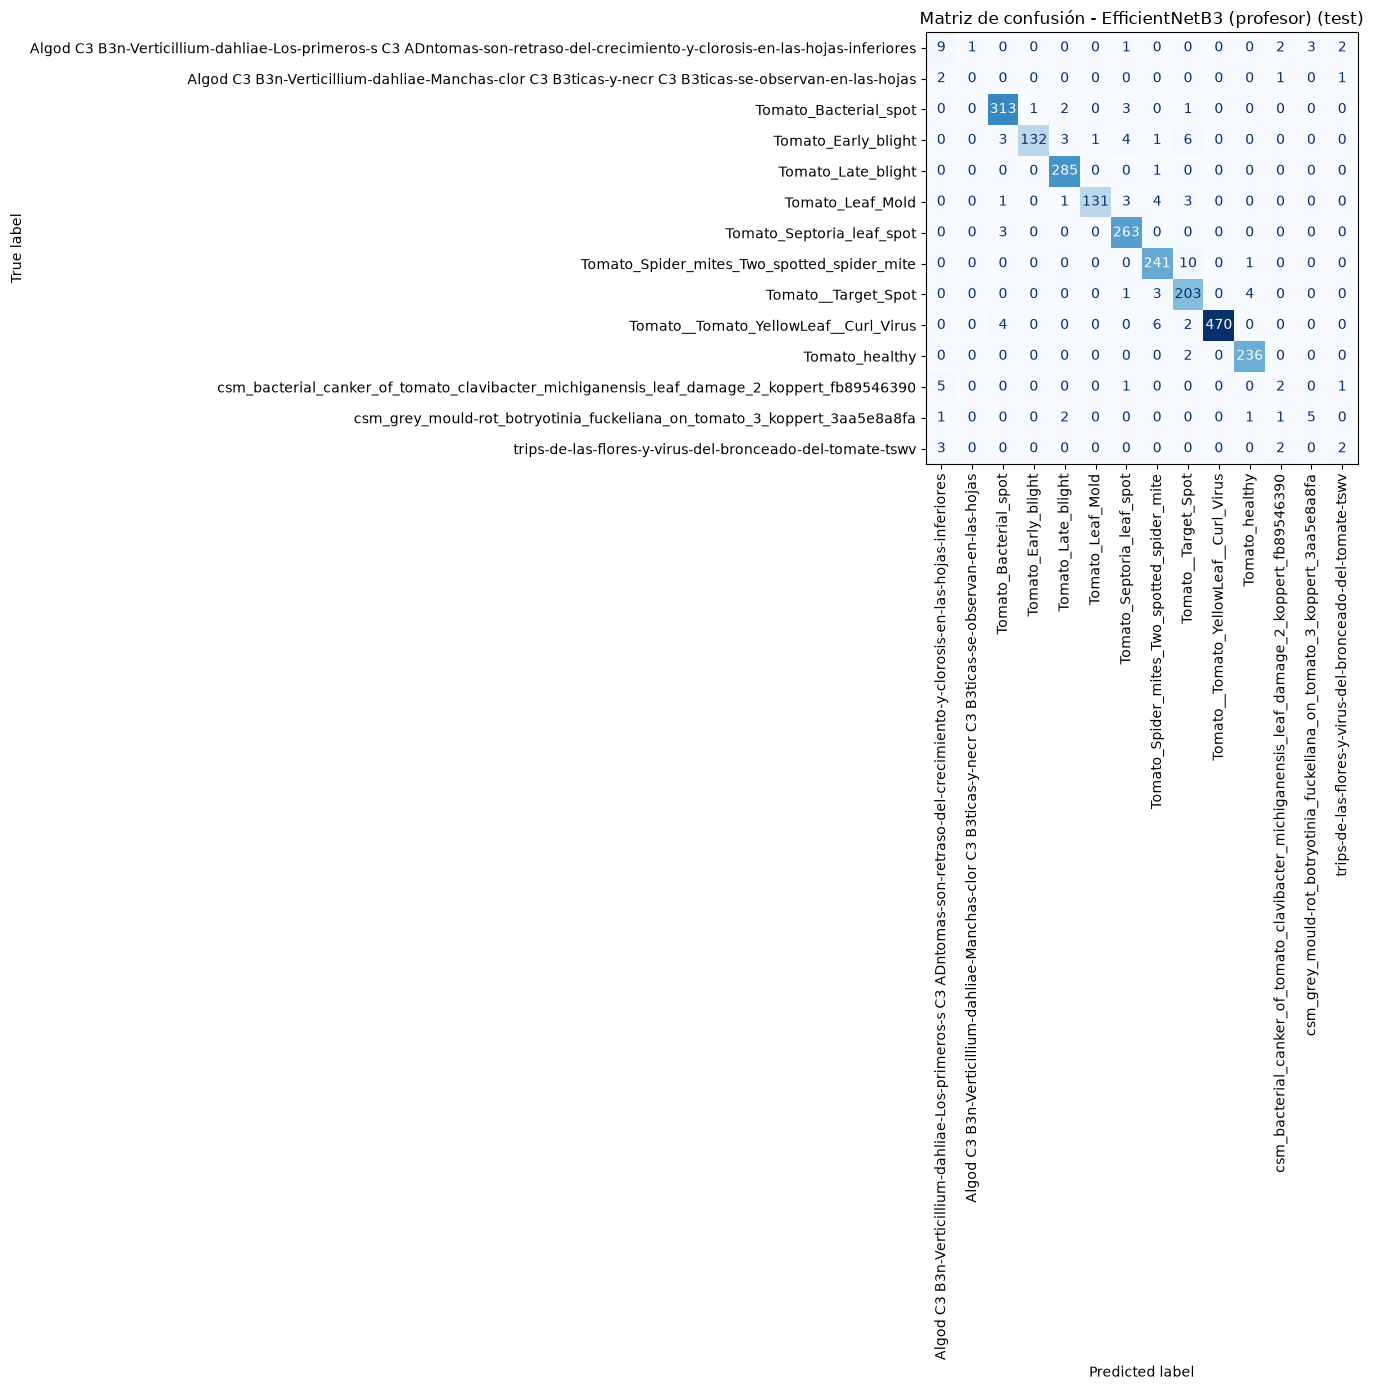

Matriz guardada en: D:\UNIVERSIDAD COOPERATIVA\9.NOVENO SEMESTRE UCC\Electiva III\modelos_multiclase\profesor_efficientnetb3_matriz_confusion.png
Valores de la matriz guardados en: D:\UNIVERSIDAD COOPERATIVA\9.NOVENO SEMESTRE UCC\Electiva III\modelos_multiclase\profesor_efficientnetb3_matriz_confusion.csv
75/75 ━━━━━━━━━━━━━━━━━━━━ 10s 120ms/step

Reporte de clasificación - MobileNetV3Small (estudiante)
                                                                                                                             precision    recall  f1-score   support

Algod C3 B3n-Verticillium-dahliae-Los-primeros-s C3 ADntomas-son-retraso-del-crecimiento-y-clorosis-en-las-hojas-inferiores       0.50      0.56      0.53        18
                       Algod C3 B3n-Verticillium-dahliae-Manchas-clor C3 B3ticas-y-necr C3 B3ticas-se-observan-en-las-hojas       0.00      0.00      0.00         4
                                                                                                 

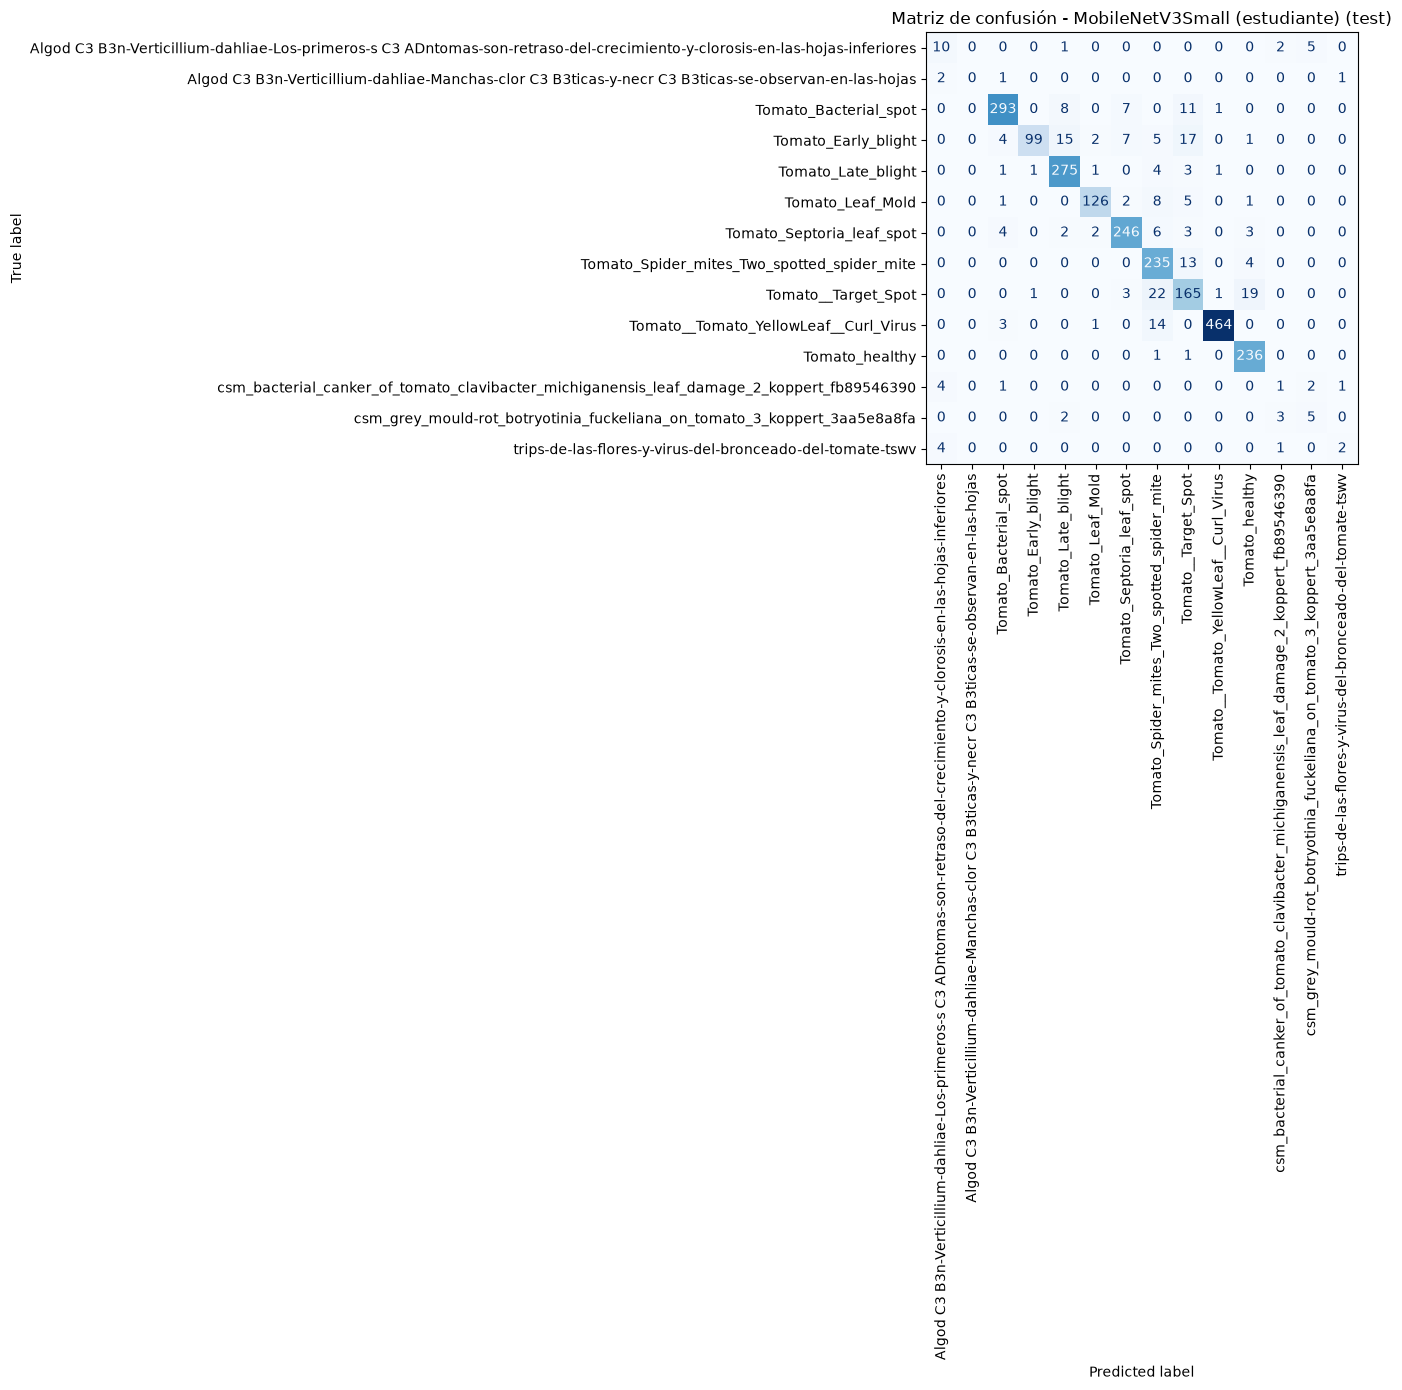

Matriz guardada en: D:\UNIVERSIDAD COOPERATIVA\9.NOVENO SEMESTRE UCC\Electiva III\modelos_multiclase\estudiante_mobilenetv3small_matriz_confusion.png
Valores de la matriz guardados en: D:\UNIVERSIDAD COOPERATIVA\9.NOVENO SEMESTRE UCC\Electiva III\modelos_multiclase\estudiante_mobilenetv3small_matriz_confusion.csv


In [11]:
# Evaluación sobre el conjunto test, que no se usó durante el entrenamiento.
y_true_test = np.concatenate([etiquetas.numpy() for _, etiquetas in test_ds])

def evaluar_y_graficar(modelo, nombre, prefijo_archivo):
    logits_test = modelo.predict(test_ds, verbose=1)
    y_pred_test = np.argmax(logits_test, axis=1)
    matriz = confusion_matrix(y_true_test, y_pred_test, labels=np.arange(len(clases)))
    reporte = classification_report(
        y_true_test, y_pred_test,
        labels=np.arange(len(clases)),
        target_names=clases,
        output_dict=True,
        zero_division=0,
    )
    print(f"\nReporte de clasificaci\u00f3n - {nombre}")
    print(classification_report(
        y_true_test, y_pred_test,
        labels=np.arange(len(clases)),
        target_names=clases,
        zero_division=0,
    ))
    figura, eje = plt.subplots(figsize=(16, 14))
    ConfusionMatrixDisplay(confusion_matrix=matriz, display_labels=clases).plot(
        ax=eje, xticks_rotation=90, cmap="Blues", colorbar=False, values_format="d"
    )
    eje.set_title(f"Matriz de confusi\u00f3n - {nombre} (test)")
    figura.tight_layout()
    ruta_figura = SALIDA / f"{prefijo_archivo}_matriz_confusion.png"
    figura.savefig(ruta_figura, dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(figura)
    ruta_matriz = SALIDA / f"{prefijo_archivo}_matriz_confusion.csv"
    pd.DataFrame(matriz, index=clases, columns=clases).to_csv(ruta_matriz, encoding="utf-8-sig")
    print("Matriz guardada en:", ruta_figura)
    print("Valores de la matriz guardados en:", ruta_matriz)
    return reporte, matriz

reporte_profesor, matriz_profesor = evaluar_y_graficar(
    profesor, "EfficientNetB3 (profesor)", "profesor_efficientnetb3"
)
reporte_estudiante, matriz_estudiante = evaluar_y_graficar(
    estudiante, "MobileNetV3Small (estudiante)", "estudiante_mobilenetv3small"
)


## 9. Tamaño, tiempo de inferencia y defensa del modelo

In [12]:
def tamano_mb(ruta):
    return Path(ruta).stat().st_size / (1024 ** 2)

print("Modelo profesor (MB):", round(tamano_mb(SALIDA / "profesor_efficientnetb3.keras"), 2))
print("Modelo estudiante (MB):", round(tamano_mb(SALIDA / "estudiante_mobilenetv3small.keras"), 2))
print("Clases en orden:", clases)
print("Accuracy test MobileNetV3Small:", round(reporte_estudiante["accuracy"], 4))
print("Macro F1 test MobileNetV3Small:", round(reporte_estudiante["macro avg"]["f1-score"], 4))
print("\nDefensa técnica:")
print("1. El profesor EfficientNetB3 aporta una referencia de mayor capacidad; el estudiante MobileNetV3Small reduce costo y tamaño.")
print("2. La destilación combina etiquetas verificadas y distribución de probabilidades del profesor a temperatura 4.")
print(f"3. L1={L1:g} y L2={L2:g} regularizan las capas densas; Dropout=0.30–0.35 y aumento de datos reducen sobreajuste.")
print("4. El test quedó separado de entrenamiento y validación; las métricas por clase y macro F1 ayudan a detectar clases débiles.")
print("5. La evidencia no demuestra generalización en campo: se recomienda validación externa por finca, dispositivo, estación y especialista.")

Modelo profesor (MB): 89.88
Modelo estudiante (MB): 4.71
Clases en orden: ['Algod C3 B3n-Verticillium-dahliae-Los-primeros-s C3 ADntomas-son-retraso-del-crecimiento-y-clorosis-en-las-hojas-inferiores', 'Algod C3 B3n-Verticillium-dahliae-Manchas-clor C3 B3ticas-y-necr C3 B3ticas-se-observan-en-las-hojas', 'Tomato_Bacterial_spot', 'Tomato_Early_blight', 'Tomato_Late_blight', 'Tomato_Leaf_Mold', 'Tomato_Septoria_leaf_spot', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Tomato__Target_Spot', 'Tomato__Tomato_YellowLeaf__Curl_Virus', 'Tomato_healthy', 'csm_bacterial_canker_of_tomato_clavibacter_michiganensis_leaf_damage_2_koppert_fb89546390', 'csm_grey_mould-rot_botryotinia_fuckeliana_on_tomato_3_koppert_3aa5e8a8fa', 'trips-de-las-flores-y-virus-del-bronceado-del-tomate-tswv']
Accuracy test MobileNetV3Small: 0.9003
Macro F1 test MobileNetV3Small: 0.6796

Defensa técnica:
1. El profesor EfficientNetB3 aporta una referencia de mayor capacidad; el estudiante MobileNetV3Small reduce costo y ta

## 10. Transfer learning y fine-tuning: por qu? funciona este entrenamiento

**Transfer learning** reutiliza caracter?sticas aprendidas previamente con ImageNet. En la primera etapa la base EfficientNetB3 queda congelada y solo aprende la cabeza clasificadora para las 14 clases del proyecto. En fine-tuning se descongela ?nicamente el bloque final y se usa una tasa de aprendizaje menor; las capas BatchNormalization siguen congeladas para conservar estad?sticas estables.

MobileNetV3Small sigue una estrategia semejante como estudiante. La destilaci?n a?ade las probabilidades suaves del profesor a la se?al de las etiquetas. Este enfoque ahorra datos y c?mputo frente a entrenar ambas redes desde cero. Los pesos ImageNet y la partici?n del proyecto son parte de la configuraci?n: la validaci?n orienta decisiones, mientras que test se reserva para la comparaci?n final.

En este cuaderno el ajuste parcial usa las ?ltimas 50 capas y `Adam(learning_rate=1e-5)`. Es un punto de partida que debe comprobarse con las curvas de entrenamiento y validaci?n; no garantiza por s? solo mejor desempe?o.

## 11. Ajuste de hiperpar?metros con validaci?n

La b?squeda compara configuraciones peque?as de Dropout, tama?o de la capa densa y tasa de aprendizaje del estudiante. Se utiliza **validation** para elegir; el conjunto test no participa en esta b?squeda. La variable de control viene desactivada para evitar iniciar varias sesiones largas de entrenamiento al ejecutar todo el notebook. C?mbiala a `True` cuando quieras realizar el experimento. Se conserva la combinaci?n con mayor `val_accuracy` y se guarda un resumen en `modelos_multiclase/`.

In [13]:
# B?squeda manual breve para la cabeza MobileNetV3Small destilada.
# Activar expl?citamente para entrenar todos los candidatos.
EJECUTAR_BUSQUEDA = False

if EJECUTAR_BUSQUEDA:
    configuraciones = [
        {"dropout": 0.20, "unidades": 128, "lr": 5e-4},
        {"dropout": 0.30, "unidades": 256, "lr": 5e-4},
        {"dropout": 0.40, "unidades": 256, "lr": 1e-4},
        {"dropout": 0.30, "unidades": 512, "lr": 1e-4},
    ]
    resultados_busqueda = []
    mejor_val = -1.0
    mejor_configuracion = None

    for numero, cfg in enumerate(configuraciones, start=1):
        entrada_busqueda = layers.Input(shape=(*TAMANO, 3), name=f"imagen_busqueda_{numero}")
        base_busqueda = tf.keras.applications.MobileNetV3Small(
            include_top=False, weights="imagenet", input_shape=(*TAMANO, 3),
            pooling=None, include_preprocessing=True,
        )
        base_busqueda.trainable = False
        x_busqueda = base_busqueda(entrada_busqueda, training=False)
        x_busqueda = layers.GlobalAveragePooling2D()(x_busqueda)
        x_busqueda = layers.Dropout(cfg["dropout"])(x_busqueda)
        x_busqueda = layers.Dense(cfg["unidades"], activation="relu",
            kernel_regularizer=regularizers.L1L2(l1=L1, l2=L2))(x_busqueda)
        x_busqueda = layers.Dropout(cfg["dropout"])(x_busqueda)
        salida_busqueda = layers.Dense(len(clases), name="logits")(x_busqueda)
        candidato = tf.keras.Model(entrada_busqueda, salida_busqueda)
        destilador_candidato = Destilador(candidato, profesor, temperatura=4.0, peso_etiqueta=0.35)
        destilador_candidato.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=cfg["lr"]))
        historial_busqueda = destilador_candidato.fit(
            train_ds, validation_data=val_ds, epochs=8,
            callbacks=[tf.keras.callbacks.EarlyStopping(
                monitor="val_accuracy", patience=2, mode="max", restore_best_weights=True
            )], verbose=1,
        )
        val_candidato = float(max(historial_busqueda.history["val_accuracy"]))
        fila = {**cfg, "val_accuracy": val_candidato}
        resultados_busqueda.append(fila)
        print(f"Candidato {numero}: {fila}")
        if val_candidato > mejor_val:
            mejor_val = val_candidato
            mejor_configuracion = fila
            candidato.save(SALIDA / "estudiante_mejor_busqueda.keras")
        del destilador_candidato, candidato, base_busqueda
        tf.keras.backend.clear_session()

    tabla_busqueda = pd.DataFrame(resultados_busqueda).sort_values("val_accuracy", ascending=False)
    display(tabla_busqueda)
    with open(SALIDA / "resultado_busqueda_hiperparametros.json", "w", encoding="utf-8") as f:
        json.dump({"mejor_configuracion": mejor_configuracion, "resultados": resultados_busqueda},
                  f, ensure_ascii=False, indent=2)
else:
    print("B?squeda sin ejecutar. Cambia EJECUTAR_BUSQUEDA = True para iniciar el experimento.")


B?squeda sin ejecutar. Cambia EJECUTAR_BUSQUEDA = True para iniciar el experimento.


## 12. Comparar el ensamble con el modelo destilado

Un ensamble combina las probabilidades de EfficientNetB3 y MobileNetV3Small mediante promedio. Puede mejorar estabilidad cuando los modelos cometen errores distintos, pero requiere ejecutar dos redes y aumenta la latencia. La comparaci?n usa el mismo conjunto test y permite decidir con evidencia si el costo adicional se justifica. Esta celda no entrena modelos.

75/75 ━━━━━━━━━━━━━━━━━━━━ 68s 902ms/step
75/75 ━━━━━━━━━━━━━━━━━━━━ 8s 109ms/step


,modelo,accuracy,macro_f1
0,Profesor EfficientNetB3,0.956594,0.730806
1,Estudiante MobileNetV3Small destilado,0.900250,0.679624
2,Ensamble (promedio de probabilidades),0.944073,0.733953


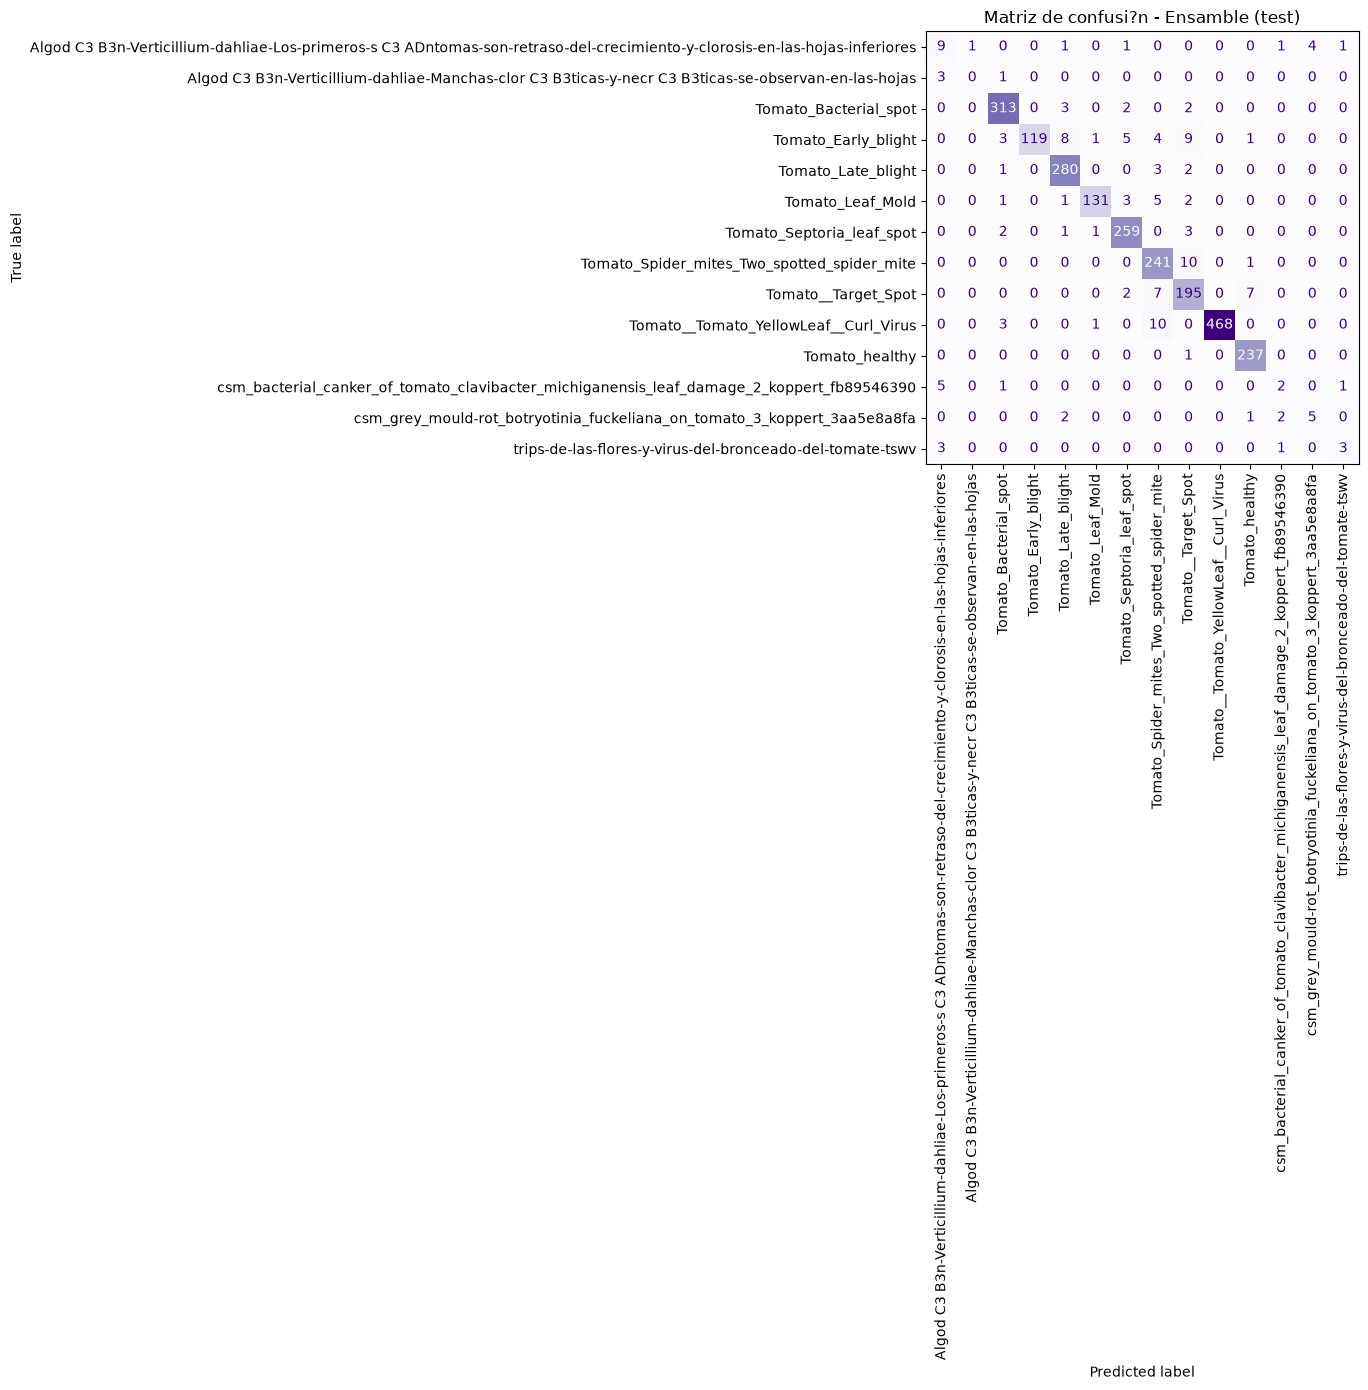

In [14]:
# Promedio de probabilidades de ambos modelos para cada imagen de test.
prob_profesor_test = tf.nn.softmax(profesor.predict(test_ds, verbose=1), axis=1).numpy()
prob_estudiante_test = tf.nn.softmax(estudiante.predict(test_ds, verbose=1), axis=1).numpy()
prob_ensamble_test = (prob_profesor_test + prob_estudiante_test) / 2.0
y_pred_ensamble = np.argmax(prob_ensamble_test, axis=1)
reporte_ensamble = classification_report(
    y_true_test, y_pred_ensamble, labels=np.arange(len(clases)),
    target_names=clases, output_dict=True, zero_division=0,
)
comparacion_modelos = pd.DataFrame([
    {"modelo": "Profesor EfficientNetB3", "accuracy": reporte_profesor["accuracy"],
     "macro_f1": reporte_profesor["macro avg"]["f1-score"]},
    {"modelo": "Estudiante MobileNetV3Small destilado", "accuracy": reporte_estudiante["accuracy"],
     "macro_f1": reporte_estudiante["macro avg"]["f1-score"]},
    {"modelo": "Ensamble (promedio de probabilidades)", "accuracy": reporte_ensamble["accuracy"],
     "macro_f1": reporte_ensamble["macro avg"]["f1-score"]},
])
display(comparacion_modelos)
comparacion_modelos.to_csv(SALIDA / "comparacion_profesor_estudiante_ensamble.csv", index=False, encoding="utf-8-sig")
matriz_ensamble = confusion_matrix(y_true_test, y_pred_ensamble, labels=np.arange(len(clases)))
figura, eje = plt.subplots(figsize=(16, 14))
ConfusionMatrixDisplay(matriz_ensamble, display_labels=clases).plot(
    ax=eje, xticks_rotation=90, cmap="Purples", colorbar=False, values_format="d"
)
eje.set_title("Matriz de confusi?n - Ensamble (test)")
figura.tight_layout()
figura.savefig(SALIDA / "ensamble_matriz_confusion.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(figura)


## 13. Preparar MobileNetV3Small para dispositivos m?viles

La conversi?n a TensorFlow Lite permite integrar el estudiante en Android o iOS. El tama?o del archivo es solo una parte de la evaluaci?n: tambi?n se deben medir latencia y desempe?o en el dispositivo de destino. La cuantizaci?n din?mica reduce el tama?o de pesos; la cuantizaci?n entera completa puede reducir m?s el costo, aunque debe validarse porque puede afectar las m?tricas. El conjunto representativo para calibraci?n se toma de train; test se mantiene reservado.

El bloque exporta TFLite float32, cuantizaci?n din?mica y, si el conversor lo admite, int8. La variable de control evita exportar autom?ticamente. El archivo `mapa_clases.json` acompa?a al modelo para traducir el ?ndice predicho a nombre de clase.

In [15]:
EXPORTAR_TFLITE = False

if EXPORTAR_TFLITE:
    ruta_tflite_float = SALIDA / "estudiante_mobilenetv3small_float32.tflite"
    conversor = tf.lite.TFLiteConverter.from_keras_model(estudiante)
    modelo_tflite_float = conversor.convert()
    ruta_tflite_float.write_bytes(modelo_tflite_float)

    conversor_dinamico = tf.lite.TFLiteConverter.from_keras_model(estudiante)
    conversor_dinamico.optimizations = [tf.lite.Optimize.DEFAULT]
    modelo_tflite_dinamico = conversor_dinamico.convert()
    ruta_tflite_dinamico = SALIDA / "estudiante_mobilenetv3small_dynamic.tflite"
    ruta_tflite_dinamico.write_bytes(modelo_tflite_dinamico)

    def datos_representativos():
        for imagenes, _ in train_ds.unbatch().batch(1).take(200):
            yield [tf.cast(imagenes, tf.float32)]

    ruta_tflite_int8 = SALIDA / "estudiante_mobilenetv3small_int8.tflite"
    try:
        conversor_int8 = tf.lite.TFLiteConverter.from_keras_model(estudiante)
        conversor_int8.optimizations = [tf.lite.Optimize.DEFAULT]
        conversor_int8.representative_dataset = datos_representativos
        conversor_int8.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
        conversor_int8.inference_input_type = tf.uint8
        conversor_int8.inference_output_type = tf.uint8
        ruta_tflite_int8.write_bytes(conversor_int8.convert())
        print("Cuantizaci?n int8 completa exportada:", ruta_tflite_int8)
    except Exception as exc:
        print("No se pudo convertir a int8 en esta versi?n/configuraci?n:", exc)

    with open(SALIDA / "mapa_clases.json", "w", encoding="utf-8") as f:
        json.dump({str(i): nombre for i, nombre in enumerate(clases)}, f, ensure_ascii=False, indent=2)
    for ruta in [ruta_tflite_float, ruta_tflite_dinamico]:
        print(ruta.name, "?", round(ruta.stat().st_size / (1024 ** 2), 2), "MB")
else:
    print("Exportaci?n sin ejecutar. Cambia EXPORTAR_TFLITE = True para generar los archivos m?viles.")


Exportaci?n sin ejecutar. Cambia EXPORTAR_TFLITE = True para generar los archivos m?viles.


### Integraci?n m?nima en una app Flutter

Instala `tflite_flutter` y `image` en la app. Copia `estudiante_mobilenetv3small_dynamic.tflite` y `mapa_clases.json` a sus assets y decl?ralos en `pubspec.yaml`. El int?rprete recibe una imagen RGB de 224?224 como tensor `[1, 224, 224, 3]` en el rango 0?255; MobileNetV3Small incluye su propio preprocesamiento. En producci?n, adapta el c?digo de abajo a la forma y tipo de entrada que indique `interpreter.getInputTensor(0)`, gestiona rotaci?n/orientaci?n de c?mara y muestra confianza adem?s de la clase.

```dart
final interpreter = await Interpreter.fromAsset('estudiante_mobilenetv3small_dynamic.tflite');
// rgb224 debe ser una lista/int tensor [1, 224, 224, 3] con valores 0..255.
final output = List.generate(1, (_) => List.filled(numeroDeClases, 0.0));
interpreter.run(rgb224, output);
final logits = output[0];
final expLogits = logits.map((x) => math.exp(x - logits.reduce((a, b) => a > b ? a : b))).toList();
final suma = expLogits.reduce((a, b) => a + b);
final scores = expLogits.map((x) => x / suma).toList();
final indice = scores.indexOf(scores.reduce((a, b) => a > b ? a : b));
final nombre = mapaClases['$indice'];
final confianza = scores[indice];
```

La representaci?n del tensor de entrada puede variar entre los archivos float32 y uint8. Consulta los detalles del tensor TFLite y escala o convierte los p?xeles seg?n corresponda; luego compara predicciones m?viles con la evaluaci?n Python antes de publicar la app.

## 14. Evaluacion avanzada y prueba de campo

El test actual mide el comportamiento dentro de la partici?n del dataset. Para estimar utilidad regional hace falta una colecci?n **externa**, con fotos tomadas en fincas, tel?fonos, iluminaci?n y etapas distintas. Guarda las im?genes por carpetas cuyo nombre coincida exactamente con las clases, solicita confirmaci?n de etiquetas a una persona experta y documenta finca, fecha, dispositivo y condiciones. No ajustes el modelo con esos datos antes de reportar el resultado.

La celda siguiente busca una carpeta opcional `datos_campo/` junto al proyecto. Si no existe, muestra instrucciones y no ejecuta una evaluaci?n ficticia. Las carpetas con nombres que no est?n en el mapa se omiten y se informan.

In [16]:
RUTA_CAMPO = PROYECTO / "datos_campo"

if not RUTA_CAMPO.exists():
    print("Crea datos_campo/<nombre_exacto_de_clase>/*.jpg con im?genes de campo etiquetadas y verificadas.")
else:
    registros_campo = []
    clases_campo_no_reconocidas = []
    for carpeta in sorted(p for p in RUTA_CAMPO.iterdir() if p.is_dir()):
        if carpeta.name not in clases:
            clases_campo_no_reconocidas.append(carpeta.name)
            continue
        etiqueta = clases.index(carpeta.name)
        for ruta in carpeta.rglob("*"):
            if ruta.is_file() and ruta.suffix.lower() in EXTENSIONES:
                registros_campo.append({"path": str(ruta), "label": etiqueta, "class_name": carpeta.name})
    if clases_campo_no_reconocidas:
        print("Carpetas ignoradas (no est?n en el mapa de clases):", clases_campo_no_reconocidas)
    if not registros_campo:
        print("No se encontraron im?genes etiquetadas con nombres de clase reconocidos.")
    else:
        df_campo = pd.DataFrame(registros_campo)
        ds_campo = crear_dataset(df_campo).prefetch(AUTOTUNE)
        y_true_campo = df_campo.label.to_numpy()
        logits_campo = estudiante.predict(ds_campo, verbose=1)
        y_pred_campo = np.argmax(logits_campo, axis=1)
        reporte_campo = classification_report(
            y_true_campo, y_pred_campo, labels=np.arange(len(clases)),
            target_names=clases, output_dict=True, zero_division=0,
        )
        print(classification_report(
            y_true_campo, y_pred_campo, labels=np.arange(len(clases)),
            target_names=clases, zero_division=0,
        ))
        matriz_campo = confusion_matrix(y_true_campo, y_pred_campo, labels=np.arange(len(clases)))
        pd.DataFrame(matriz_campo, index=clases, columns=clases).to_csv(
            SALIDA / "evaluacion_campo_matriz_confusion.csv", encoding="utf-8-sig"
        )
        print("Accuracy campo:", round(reporte_campo["accuracy"], 4))
        print("Macro F1 campo:", round(reporte_campo["macro avg"]["f1-score"], 4))


Crea datos_campo/<nombre_exacto_de_clase>/*.jpg con im?genes de campo etiquetadas y verificadas.


### Protocolo para informar la prueba de campo

- Separar fincas o fechas completas entre desarrollo y evaluaci?n cuando haya varias fuentes; evitar que r?fagas de la misma planta queden repartidas entre conjuntos.
- Registrar n?mero de im?genes por clase, fuente, dispositivo, fecha y condiciones; anotar im?genes ambiguas o con m?s de una enfermedad.
- Informar accuracy, precision, recall y F1 por clase, macro F1, matriz de confusi?n e intervalos de confianza. Revisar falsos negativos con un agr?nomo.
- Comparar la versi?n TFLite en el tel?fono real: latencia mediana y percentil 95, memoria, tama?o del archivo y desempe?o sobre las mismas im?genes.
- Una evaluaci?n de campo peque?a es evidencia preliminar; no demuestra capacidad diagn?stica general. Mantener revisi?n experta y mecanismo para casos inciertos.

## 15. Resumen para sustentación

**Decisión de arquitectura:** se eligió EfficientNetB3 como profesor por su mayor capacidad de representación y MobileNetV3Small como estudiante por su tamaño y velocidad adecuados para dispositivos con recursos limitados. Se inicializan con pesos ImageNet y se adaptan a las categorías de las carpetas etiquetadas.

**Regularización:** aumento de datos aleatorio, Dropout, penalizaciones L1 y L2 en las capas densas, ajuste fino con tasa de aprendizaje baja, EarlyStopping y restauración de los mejores pesos. L1 favorece pesos escasos; L2 limita magnitudes grandes.

**Destilación:** el estudiante minimiza una combinación de pérdida supervisada real y divergencia entre la distribución suavizada del profesor y la del estudiante. Las etiquetas reales conservan peso 0.35 y las probabilidades del profesor peso 0.65, con temperatura 4.

**Validez:** se informan métricas del conjunto test por clase y macro promedio. Para sostener una afirmación de desempeño externo hace falta una prueba independiente de otro origen y revisión de posibles duplicados casi idénticos o sesgos de fuente. Este prototipo clasifica imágenes del dataset y no es un diagnóstico agronómico autónomo.